# Taxi Fare Prediction

**Business question**: given a pickup and dropoff location, a pickup time and the number of passengers, what will the fare be? Ride-hailing companies such as Uber and Lyft solve this pricing problem in production.

**Dataset**: NYC taxi trips from 2009 to 2015 (`train_fare.csv`, `test_fare.csv`), with pickup and dropoff coordinates, passenger count and time features. Target: `fare_amount`.

This is a **regression** problem.

**Pipeline**: this notebook → FastAPI → Streamlit → Docker → GitHub Actions CI/CD → AWS → Databricks.

**Known data limits**:
- Every fare in this file is between \$3.30 and \$30.27, so expensive trips (such as airport flat fares) were trimmed out before we got it. The model can't predict fares above about \$30.
- The file has 1,048,575 rows, which is Excel's row limit, so it's a sample of the original data, not the full dataset.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Shared feature code. taxi_features.py must sit in the same folder as this notebook.
from taxi_features import RAW_COLUMNS, NYC_BOX, FIRST_YEAR, LAST_YEAR, build_features, trip_to_row

print('scikit-learn', sklearn.__version__)

scikit-learn 1.7.2


In [2]:
traindf = pd.read_csv('train_fare.csv')
testdf = pd.read_csv('test_fare.csv')
print(traindf.shape, testdf.shape)
traindf.head()

(1048575, 14) (9914, 13)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,day,dayOfWeek,hour,timeOfDayMid.Day,timeOfDayMorning,timeOfDayNight
0,4.5,-73.844311,40.721319,-73.841610,40.712278,1,1,6,15,2,17,0,0,0
1,16.9,-74.016048,40.711303,-73.979268,40.782004,1,2,1,5,3,16,0,0,0
2,5.7,-73.982738,40.761270,-73.991242,40.750562,2,3,8,18,5,0,0,0,1
3,7.7,-73.987130,40.733143,-73.991567,40.758092,1,4,4,21,7,4,0,1,0
4,5.3,-73.968095,40.768008,-73.956655,40.783762,1,2,3,9,3,7,0,1,0


## 1. Clean the data

- Keep only trips inside a rough NYC box, because GPS errors can put trips far outside the city.
- Remove impossible fares (`<= 0` or `> 250`).
- Remove trips where pickup and dropoff are identical, which are likely bad data.
- Keep 1 to 6 passengers. A few rows have 0 or 9, which isn't a real taxi trip.

In [3]:
def clean(df):
    b = NYC_BOX
    df = df[df['pickup_longitude'].between(b['lon_min'], b['lon_max'])]
    df = df[df['dropoff_longitude'].between(b['lon_min'], b['lon_max'])]
    df = df[df['pickup_latitude'].between(b['lat_min'], b['lat_max'])]
    df = df[df['dropoff_latitude'].between(b['lat_min'], b['lat_max'])]
    df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 250)]
    df = df[df['dropoff_longitude'] != df['pickup_longitude']]
    df = df[df['dropoff_latitude'] != df['pickup_latitude']]
    df = df[df['passenger_count'].between(1, 6)]
    return df


traindf = clean(traindf)
print('Rows after cleaning:', traindf.shape[0])
print('Fare range: $%.2f to $%.2f' % (traindf['fare_amount'].min(), traindf['fare_amount'].max()))

Rows after cleaning: 1033148
Fare range: $3.30 to $30.27


## 2. Features


- **Trip distance in km** uses the Haversine formula, which turns coordinates into a real distance on the Earth's surface. Raw differences in degrees aren't a real distance, because one degree of longitude covers a different distance depending on latitude.
- **Distance from landmarks** (downtown, JFK, Newark and LaGuardia airports) lets the model pick up airport and Manhattan pricing patterns.
- Raw coordinates are dropped once the distances are computed from them.

In [4]:
build_features(traindf[RAW_COLUMNS].head())

,passenger_count,year,month,day,dayOfWeek,hour,timeOfDayMid.Day,timeOfDayMorning,timeOfDayNight,trip_distance_km,downtown_pickup_km,downtown_dropoff_km,jfk_pickup_km,jfk_dropoff_km,ewr_pickup_km,ewr_dropoff_km,lgr_pickup_km,lgr_dropoff_km
0,1,1,6,15,2,17,0,0,0,1.030764,13.682770,13.889803,10.050302,9.079682,28.091624,28.213472,5.829651,6.849567
1,1,2,1,5,3,16,0,0,0,8.450134,0.874172,7.881560,21.084094,22.599351,13.607397,19.406889,13.928323,9.297165
2,2,3,8,18,5,0,0,0,1,1.389525,5.603895,4.243449,21.336886,21.224282,18.035921,16.887030,9.544015,10.437768
3,1,4,4,21,7,4,0,1,0,2.799270,2.662028,5.041393,19.909129,21.723578,16.545552,17.212649,10.683809,10.323589
4,1,2,3,9,3,7,0,1,0,1.999157,6.800820,8.799925,20.859196,21.379469,19.473218,21.145380,8.263873,7.455377


## 3. Quick EDA

Sanity check: the fare should generally rise with distance.

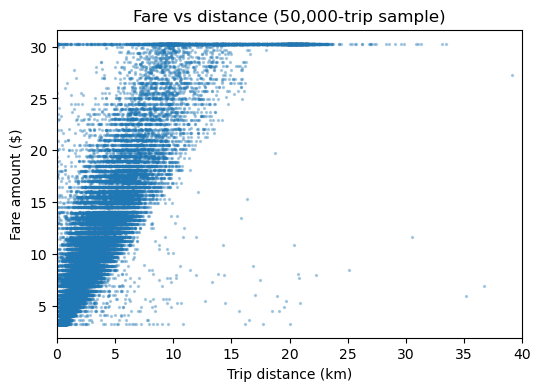

In [5]:
sample = build_features(traindf[RAW_COLUMNS].sample(50_000, random_state=1))
plt.figure(figsize=(6, 4))
plt.scatter(sample['trip_distance_km'], traindf.loc[sample.index, 'fare_amount'], s=2, alpha=0.3)
plt.xlabel('Trip distance (km)')
plt.ylabel('Fare amount ($)')
plt.title('Fare vs distance (50,000-trip sample)')
plt.xlim(0, 40)
plt.show()

## 4. Split

The split is 90% for training and 10% for validation. The model never sees the validation trips during training, so its score on them is an honest measure of how it does on new trips.

In [6]:
X = traindf[RAW_COLUMNS]
y = traindf['fare_amount'].values
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.10, random_state=1)
print('Train:', X_train.shape, '| Validate:', X_val.shape)


def score(name, preds):
    return {
        'model': name,
        'MAE': round(mean_absolute_error(y_val, preds), 3),
        'RMSE': round(float(np.sqrt(mean_squared_error(y_val, preds))), 3),
        'R2': round(r2_score(y_val, preds), 3),
    }


results = []

Train: (929833, 13) | Validate: (103315, 13)


## 5. Baselines

- **Always guess the average fare.** Any model has to beat this to be useful.
- **Linear regression.** This is the simplest real model.

In [7]:
results.append(score('Always guess the average', np.full(len(y_val), y_train.mean())))

linear = Pipeline([
    ('features', FunctionTransformer(build_features)),
    ('model', LinearRegression()),
])
linear.fit(X_train, y_train)
results.append(score('Linear regression', linear.predict(X_val)))
pd.DataFrame(results)

,model,MAE,RMSE,R2
0,Always guess the average,5.036,6.776,-0.000
1,Linear regression,2.508,4.078,0.638


## 6. Random Forest (the model we deploy)

One sklearn `Pipeline` holds both steps: building the features and the model. The saved file therefore takes **raw trips** in and gives fares out, which is all the API needs.

The settings are chosen so the saved file fits on GitHub, which has a 100 MB limit:
- `n_estimators=100`: 100 trees. More trees barely improved the score but made the file much bigger.
- `max_depth=15` and `min_samples_leaf=20`: these stop each tree growing tiny branches that only memorise a handful of trips. That keeps the file smaller and the model slightly more accurate.

Training takes several minutes on a laptop.

In [8]:
rf_pipeline = Pipeline([
    ('features', FunctionTransformer(build_features)),
    ('model', RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=20,
                                    n_jobs=-1, random_state=42)),
])
rf_pipeline.fit(X_train, y_train)
results.append(score('Random Forest', rf_pipeline.predict(X_val)))
pd.DataFrame(results)

,model,MAE,RMSE,R2
0,Always guess the average,5.036,6.776,-0.000
1,Linear regression,2.508,4.078,0.638
2,Random Forest,1.453,2.420,0.872


## 7. Neural network (your original approach, optional)

This section runs only if TensorFlow is installed. If it isn't, the cell prints a message and the rest of the notebook still runs. We don't deploy the neural network, because the Random Forest is about as accurate and much lighter to serve: no TensorFlow in the Docker image.

In [ ]:
try:
    from tensorflow import keras
    from sklearn.preprocessing import MinMaxScaler

    feats_train = build_features(X_train)
    feats_val = build_features(X_val)
    scaler = MinMaxScaler().fit(feats_train)

    nn = keras.Sequential([keras.Input(shape=(feats_train.shape[1],))])
    for units in [256, 128, 64, 32, 8]:
        nn.add(keras.layers.Dense(units, activation='relu'))
        nn.add(keras.layers.BatchNormalization())
    nn.add(keras.layers.Dense(1))
    nn.compile(loss='mse', optimizer='adam', metrics=['mae'])

    history = nn.fit(scaler.transform(feats_train), y_train, batch_size=256, epochs=20, verbose=1,
                     validation_data=(scaler.transform(feats_val), y_val),
                     callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='validation')
    plt.title('Neural network loss'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend(); plt.show()

    results.append(score('Neural network', nn.predict(scaler.transform(feats_val), verbose=0).flatten()))
except ImportError:
    print('TensorFlow not installed - skipping the neural network (not needed for deployment).')

## 8. Compare and choose

In [9]:
comparison = pd.DataFrame(results).set_index('model')
comparison

,MAE,RMSE,R2
model,,,
Always guess the average,5.036,6.776,-0.000
Linear regression,2.508,4.078,0.638
Random Forest,1.453,2.420,0.872


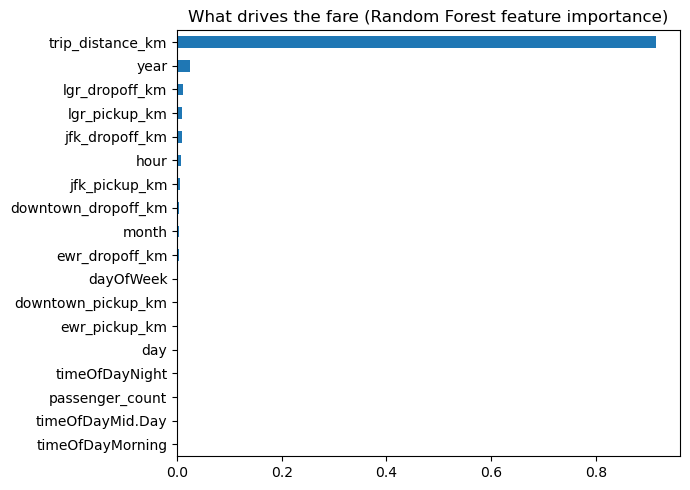

In [10]:
importances = pd.Series(
    rf_pipeline.named_steps['model'].feature_importances_,
    index=build_features(X_train.head()).columns,
).sort_values()

plt.figure(figsize=(7, 5))
importances.plot(kind='barh')
plt.title('What drives the fare (Random Forest feature importance)')
plt.tight_layout()
plt.show()

## 9. Save the pipeline and config for the API

- `taxi_pipeline.joblib` is the full pipeline: feature building plus the Random Forest. It's compressed to keep it under GitHub's 100 MB limit.
- `taxi_config.json` holds the input columns, valid ranges, metrics and versions. The API reads it to check inputs and to show the model's details.

In [11]:
joblib.dump(rf_pipeline, 'taxi_pipeline.joblib', compress=3)

rf_row = comparison.loc['Random Forest']
config = {
    'model': 'RandomForestRegressor inside sklearn Pipeline',
    'sklearn_version': sklearn.__version__,
    'input_columns': RAW_COLUMNS,
    'valid_ranges': {
        'longitude': [NYC_BOX['lon_min'], NYC_BOX['lon_max']],
        'latitude': [NYC_BOX['lat_min'], NYC_BOX['lat_max']],
        'passenger_count': [1, 6],
        'pickup_year': [FIRST_YEAR, LAST_YEAR],
    },
    'training_fare_range': [float(traindf['fare_amount'].min()), float(traindf['fare_amount'].max())],
    'validation_metrics': {'MAE': float(rf_row['MAE']), 'RMSE': float(rf_row['RMSE']), 'R2': float(rf_row['R2'])},
    'baseline_MAE': float(comparison.loc['Always guess the average', 'MAE']),
    'rows_used': int(len(traindf)),
}
with open('taxi_config.json', 'w') as f:
    json.dump(config, f, indent=2)

import os
print('Saved taxi_pipeline.joblib (%.0f MB) and taxi_config.json' % (os.path.getsize('taxi_pipeline.joblib') / 1e6))

Saved taxi_pipeline.joblib (31 MB) and taxi_config.json


## 10. Reload test: the same thing the API will do

This loads the saved file fresh and prices one trip the way a user would describe it: two points and a pickup time.

In [12]:
loaded = joblib.load('taxi_pipeline.joblib')

# Times Square to JFK airport, 2 passengers, Friday 6pm in 2014
trip = trip_to_row(pickup_lon=-73.9855, pickup_lat=40.7580,
                   dropoff_lon=-73.7781, dropoff_lat=40.6413,
                   passenger_count=2, pickup_datetime='2014-06-13T18:00:00')
print(trip.T)
print('Predicted fare: $%.2f' % loaded.predict(trip)[0])

# Short hop in Midtown
short = trip_to_row(-73.9855, 40.7580, -73.9772, 40.7527, 1, '2013-03-05T09:30:00')
print('Short Midtown trip: $%.2f' % loaded.predict(short)[0])

                         0
pickup_longitude  -73.9855
pickup_latitude    40.7580
dropoff_longitude -73.7781
dropoff_latitude   40.6413
passenger_count     2.0000
year                6.0000
month               6.0000
day                13.0000
dayOfWeek           6.0000
hour               18.0000
timeOfDayMid.Day    0.0000
timeOfDayMorning    0.0000
timeOfDayNight      1.0000
Predicted fare: $30.11
Short Midtown trip: $7.00


## 11. Predictions for the test set

In [13]:
test_predictions = loaded.predict(testdf[RAW_COLUMNS])
pd.DataFrame({'fare_amount': test_predictions.round(2)}).to_csv('predictions.csv', index=False)
print('Saved predictions.csv for', len(test_predictions), 'test trips')

Saved predictions.csv for 9914 test trips


## Results summary

Fill this in from section 8 after running, for the README and LinkedIn:

- Guessing the average fare is off by about \$X per trip.
- The Random Forest is off by about \$Y per trip (R² = Z), so it explains Z×100% of the variation in fares.

**Next step**: the FastAPI app, which loads `taxi_pipeline.joblib` and uses `trip_to_row()` from `taxi_features.py`.